# Used Car Price Prediction
### Cleaning, exploratory analysis, and regression model comparison

The supplied data contain brand, year, engine size, fuel, transmission, mileage, condition, price, and model. We predict listed price from the available attributes. The random holdout evaluates interpolation within this dataset; it does not establish market value for a different time, source, or region.

In [1]:
import warnings; warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np, pandas as pd, seaborn as sns, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
sns.set_theme(style='whitegrid',palette='colorblind')

In [2]:
df = pd.read_csv(Path('.')/'car_price_prediction_.csv')
df.columns=df.columns.str.strip()
print('Shape:',df.shape)
display(df.head())
print('Dtypes:')
print(df.dtypes)
print('Nulls:')
print(df.isna().sum())
print('Duplicate rows:',df.duplicated().sum())
for c in ['Brand','Fuel Type','Transmission','Condition','Model']:
    df[c]=df[c].astype('string').str.strip().str.title()
df=df.drop_duplicates().copy()
for c in ['Year','Engine Size','Mileage','Price']:
    df[c]=pd.to_numeric(df[c],errors='coerce')
current_year=pd.Timestamp.now().year
df['car_age']=current_year-df['Year']
df=df[df['Price'].gt(0) & df['car_age'].between(0,60)]
print('Cleaned shape:',df.shape,'| Year reference:',current_year)
display(df.describe(include='all').T)

Shape: (2500, 10)


,Car ID,Brand,Year,Engine Size,Fuel Type,Transmission,Mileage,Condition,Price,Model
0,1,Tesla,2016,2.3,Petrol,Manual,114832,New,26613.92,Model X
1,2,BMW,2018,4.4,Electric,Manual,143190,Used,14679.61,5 Series
2,3,Audi,2013,4.5,Electric,Manual,181601,New,44402.61,A4
3,4,Tesla,2011,4.1,Diesel,Automatic,68682,New,86374.33,Model Y
4,5,Ford,2009,2.6,Diesel,Manual,223009,Like New,73577.10,Mustang


Dtypes:
Car ID            int64
Brand               str
Year              int64
Engine Size     float64
Fuel Type           str
Transmission        str
Mileage           int64
Condition           str
Price           float64
Model               str
dtype: object
Nulls:
Car ID          0
Brand           0
Year            0
Engine Size     0
Fuel Type       0
Transmission    0
Mileage         0
Condition       0
Price           0
Model           0
dtype: int64
Duplicate rows: 0
Cleaned shape: (2500, 11) | Year reference: 2026


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Car ID,2500.0,NaN,NaN,NaN,1250.5,721.83216,1.0,625.75,1250.5,1875.25,2500.0
Brand,2500,7,Toyota,374,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,2500.0,NaN,NaN,NaN,2011.6268,6.9917,2000.0,2005.0,2012.0,2018.0,2023.0
Engine Size,2500.0,NaN,NaN,NaN,3.46524,1.432053,1.0,2.2,3.4,4.7,6.0
Fuel Type,2500,4,Diesel,655,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transmission,2500,2,Manual,1308,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Mileage,2500.0,NaN,NaN,NaN,149749.8448,87919.952034,15.0,71831.5,149085.0,225990.5,299967.0
Condition,2500,3,Used,855,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,2500.0,NaN,NaN,NaN,52638.022532,27295.833455,5011.27,28908.485,53485.24,75838.5325,99982.59
Model,2500,28,Fiesta,103,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### EDA
Check skew and outliers in the price distribution. Boxplots compare price distributions by fuel type; scatter points show how price relates to age. These plots are descriptive and do not imply causal effects.

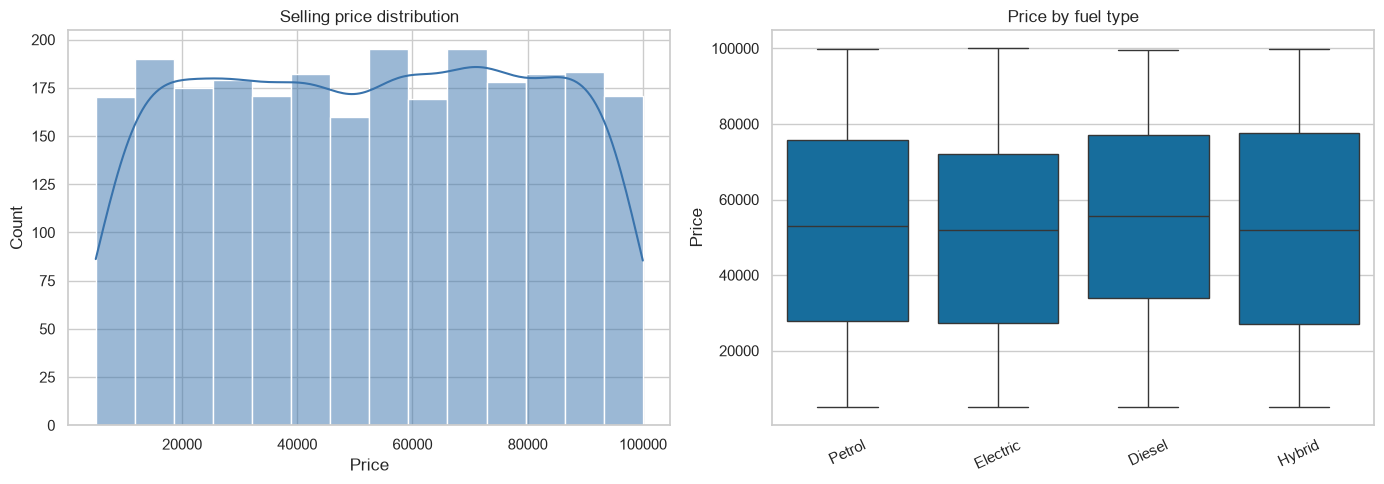

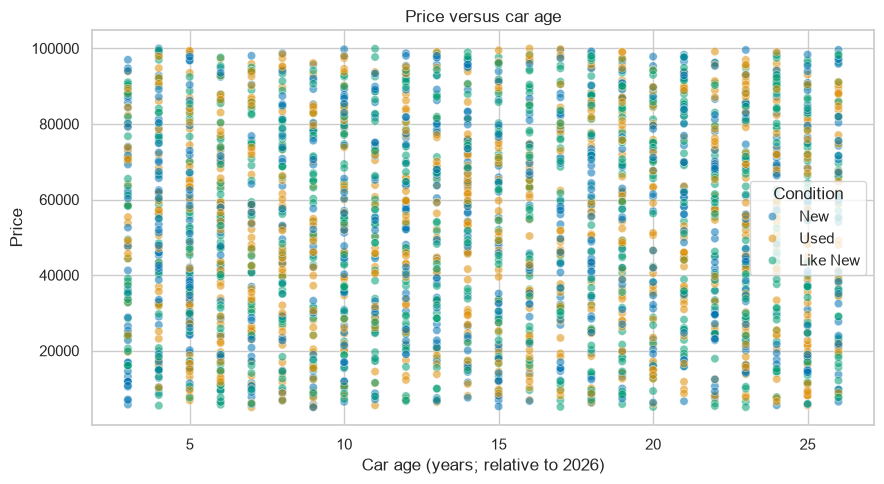

In [3]:
fig,axes=plt.subplots(1,2,figsize=(14,5))
sns.histplot(df['Price'],kde=True,ax=axes[0],color='#3973ac'); axes[0].set(title='Selling price distribution',xlabel='Price')
sns.boxplot(data=df,x='Fuel Type',y='Price',ax=axes[1]); axes[1].set(title='Price by fuel type',xlabel='',ylabel='Price'); axes[1].tick_params(axis='x',rotation=25)
plt.tight_layout(); plt.show()
plt.figure(figsize=(9,5)); sns.scatterplot(data=df,x='car_age',y='Price',hue='Condition',alpha=.55)
plt.title('Price versus car age'); plt.xlabel(f'Car age (years; relative to {current_year})'); plt.ylabel('Price'); plt.tight_layout(); plt.show()

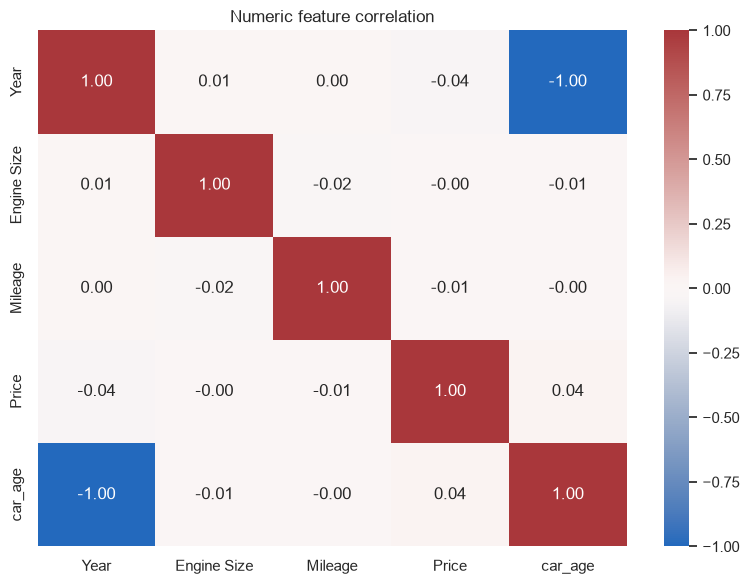

In [4]:
numeric=df.select_dtypes(include='number').drop(columns=['Car ID'],errors='ignore')
plt.figure(figsize=(8,6)); sns.heatmap(numeric.corr(),annot=True,cmap='vlag',center=0,fmt='.2f')
plt.title('Numeric feature correlation'); plt.tight_layout(); plt.show()

### Modeling
We exclude the record identifier because it is not a meaningful price attribute. Numeric missing values use the training median; categorical values use the most frequent training value and one-hot encoding. Ridge provides a regularized linear baseline, and a random forest captures nonlinear patterns. Both use the same 80/20 split and feature set.

In [5]:
target='Price'
features=['Brand','Year','Engine Size','Fuel Type','Transmission','Mileage','Condition','Model','car_age']
X=df[features]; y=df[target]
cat=X.select_dtypes(include=['object','string','category']).columns.tolist(); num=[c for c in X.columns if c not in cat]
pre=ColumnTransformer([('num',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num),('cat',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('ohe',OneHotEncoder(handle_unknown='ignore'))]),cat)])
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,random_state=42)
models={'Ridge Regression':Ridge(alpha=1.0),'Random Forest':RandomForestRegressor(n_estimators=300,min_samples_leaf=2,random_state=42,n_jobs=-1)}
fitted={}; rows=[]
for name,reg in models.items():
    pipe=Pipeline([('preprocess',pre),('model',reg)]); pipe.fit(X_train,y_train); pred=pipe.predict(X_test); fitted[name]=pipe
    rows.append({'Model':name,'MAE':mean_absolute_error(y_test,pred),'RMSE':np.sqrt(mean_squared_error(y_test,pred)),'R2':r2_score(y_test,pred)})
results=pd.DataFrame(rows).sort_values('RMSE'); display(results.round(3))
best_name=results.iloc[0]['Model']; best=fitted[best_name]; best_pred=best.predict(X_test)
print('Selected by lowest holdout RMSE:',best_name)

,Model,MAE,RMSE,R2
0,Ridge Regression,23873.875,27788.760,-0.019
1,Random Forest,24296.377,28208.886,-0.050


Selected by lowest holdout RMSE: Ridge Regression


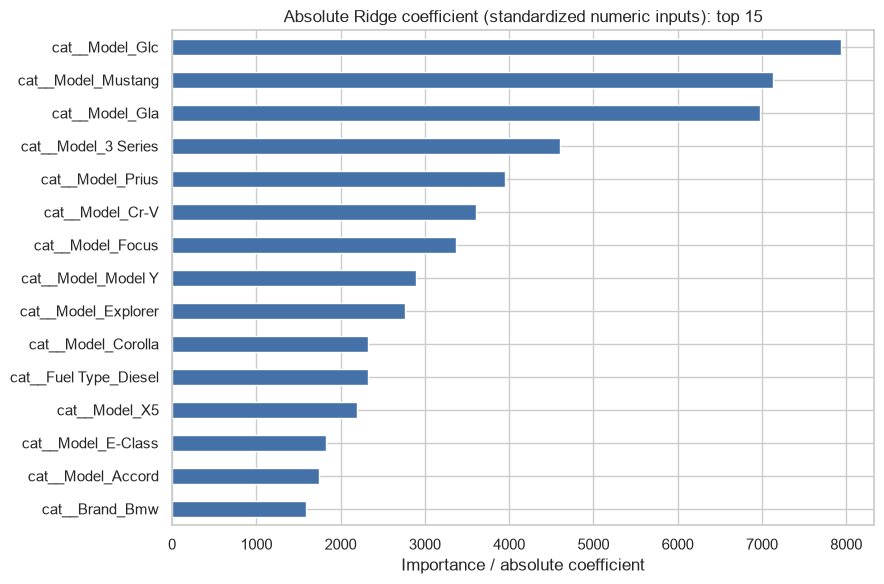

In [6]:
# Rank the selected model's fitted features. Forest importance is used for a forest;
# absolute Ridge coefficients are used if Ridge wins the holdout comparison.
transformer=best.named_steps['preprocess']
encoded=transformer.get_feature_names_out()
if best_name == 'Random Forest':
    scores=best.named_steps['model'].feature_importances_
    title='Random Forest feature importance'
else:
    scores=np.abs(best.named_steps['model'].coef_)
    title='Absolute Ridge coefficient (standardized numeric inputs)'
importance=pd.Series(scores,index=encoded).sort_values(ascending=False).head(15).sort_values()
plt.figure(figsize=(9,6)); importance.plot(kind='barh',color='#4472a8')
plt.title(f'{title}: top 15'); plt.xlabel('Importance / absolute coefficient'); plt.tight_layout(); plt.show()

## Conclusion
Use the metrics table to compare errors in the dataset?s price units (MAE/RMSE) and explained variance (R?). The model selected by lowest test RMSE is the best of these two on this split. Feature importance indicates which encoded inputs the forest used for its splits; it is not a causal effect or a guarantee that changing a feature changes price by that amount.